# HD VILLAGE: NEBULA DEG Case vs Control

Same logic, functions and parameters as `Handsaker_DEG_repeats_NEBULA.ipynb`, on the VILLAGE dataset and with `Status` as the response.

For each group of cells (analysed separately), one model per gene:

```
counts ~ RESPONSE + COVARIATES [+ factors] + (1 | DONOR),   offset = total_counts
```

and the coefficient of `RESPONSE` is tested.
* Default: categorical `Status`, `log2FC` of `Case` (`RESPONSE_TESTED`) vs `Control` (`RESPONSE_BASELINE`). Every donor has one status, so the test is between donors.
* A numeric response (any numeric obs column) also works: `log2FC` per unit of it.

**Groups**: the cell types are the values of `CELLTYPE_COL`. With `MERGE_CELL_TYPES = False` every cell type is analysed on its own (cell types starting with `-` are removed); with `True` only the merged groups of `CELLTYPE_MERGE` are analysed (e.g. Matrix_D1 + Matrix_D2 → Matrix) and the other cell types are ignored. Only groups that have factors are kept (e.g. a BICAN PCA file of the same name).

**Factors** (`FACTOR_METHOD`), computed on reference cells (`FACTORS_FROM`: `"bican"` or `"healthy_samples"` = Control cells of this dataset) and transferred to every cell, so the HD cases never shape them:
* `"pca"`: PCs (BICAN PCA from `PCA_on_BICAN.ipynb`, or fitted here); the model uses PC_1 … knee of the scree plot.
* `"cnmf"`: GEP usages on cNMF spectra trained outside this notebook (`CNMF_SPECTRA`).
* `"dv_score"`: dorsal–ventral position score from genes with a stable spatial gradient in BICAN health and XDP (as in `NucSeq_DEG_factors.ipynb`).
* `"none"`: baseline only.

`FACTOR_ASSOCIATION` then keeps all factors, only those associated with the response, or drops those.

**Models** per group: `baseline` (no factors) and one factor model.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import h5py
from adjustText import adjust_text
import decoupler as dc

from utils import reference_pca
from utils import DEG          # ATTENTION: imports pertpy, which switches matplotlib to Agg -> must come before %matplotlib inline

# NEBULA runner of generalisable_DEG: fits gene chunks in parallel in R, returns NEBULA's table
sys.path.insert(0, "/home/gdallagl/myworkdir/data/_old/generalisable_DEG")
from functions import nebula as nebula_runner

%matplotlib inline

ADATA_PATH = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad"
DONOR_COL = "DONOR"
LIBRARY_SIZE_COL = "total_counts"

# ------------------------------------------------------------------------------------------ groups of cells
# column with the cell types
CELLTYPE_COL = "ct_for_deg"
# False: every cell type of CELLTYPE_COL is analysed on its own (cell types starting with "-" are removed)
# True:  only the merged groups of CELLTYPE_MERGE are analysed, all other cell types are ignored
# ATTNETION: a cell tyep cannpot be in mroe then one group, other wise dorn knwohee to put it --> MAKE MULTIPLE RUNS
MERGE_CELL_TYPES = True
CELLTYPE_MERGE = {               # merged group -> cell types pooled into it
    
    # "Matrix": ["Matrix_D1", "Matrix_D2"],
    # "Patch":  ["Patch_D1", "Patch_D2"],
    # "eMSN_D1D2": ["eMSN_D1D2"],

    "MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "-Phase_D"]
}
# example, all MSNs + phase D as one group:
#   CELLTYPE_MERGE = {"MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "-phase_D"]}
#   (then remove "msn_subtype" from COVARIATES: phase D cells have no D1/D2 label, so that level would absorb the long-repeat effect)
# ATTENTION: only groups with factors are analysed: FACTORS_FROM = "bican" needs a BICAN file of the same name
# in BICAN_PCA_DIR (made by PCA_on_BICAN.ipynb), dv_score needs an entry in DV_GRADIENT_CT

# ------------------------------------------------------------------------------------------ tested variable
RESPONSE = "Status"              # any obs column; categorical (e.g. "Status") or numeric
RESPONSE_TYPE = "categorical"    # "numeric" or "categorical"
RESPONSE_BASELINE = "Control"    # categorical only: reference level
RESPONSE_TESTED = "Case"         # categorical only: level tested against the baseline

# ------------------------------------------------------------------------------------------ covariates
# column -> numeric / categorical; covariates constant in a group are dropped
# village = pool of donors processed together (see "Prepare variables")
COVARIATES = {"Age": "numeric", "Sex": "categorical", "pct_counts_mt": "numeric", "msn_subtype": "categorical", "village": "categorical"}

# z-scored over the model cells of each group (only their own coefficients change, not the tested one)
STANDARDISE = ["Age", "pct_counts_mt"]
STANDARDISE_FACTORS = True # eg PCs

# ------------------------------------------------------------------------------------------ cells and genes
MIN_CELLS_PER_DONOR = 10     # donors with fewer model cells in a group are removed from that group
MIN_DONORS = 4               # groups with fewer donors left in either level of a categorical response (numeric: in total) are skipped
MIN_COUNTS_PER_GENE = 50     # gene tested if >= this many counts AND detected in >= n_donors x MIN_CELLS_PER_DONOR cells

# genes forced to be tested
HANDSAKER_GENES_DIR = "/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all"
FORCE_KEEP_PHASES = ["c_plus", "c_minus", "d"]   # Handsaker phase genes tested anyway, if detected in >= 1 cell

# ------------------------------------------------------------------------------------------ factors
FACTOR_METHOD = "pca"            # "none", "pca", "cnmf", "dv_score"
FACTORS_FROM = "bican"           # pca / cnmf reference: "bican" or "healthy_samples" (Control cells of this dataset)


# factors associated with the response (LMM factor ~ response + covariates + (1|donor))
FACTOR_ASSOCIATION = "all"       # "all": keep every factor | "only_associated": keep only them | "drop_associated": remove them
ASSOC_FDR = 0.05                 # associated = FDR below this ...
ASSOC_MIN_ABS_BETA = 0.1         # ... and |beta| >= this (factor SDs per unit of the response, or tested vs baseline)

# pca: BICAN files, or the parameters to fit it on the Control cells of this dataset
BICAN_PCA_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican"   # from PCA_on_BICAN.ipynb
MIN_CELLS_PER_GENE_REF = 5       # healthy_samples: same PCA steps as the BICAN notebook
TARGET_SUM = 1e4
N_HVG = 3000
N_PCS = 50
SEED = 0
N_PCS_TO_TEST = 20               # PCs tested for association with the response (at least up to the knee)

# cnmf: spectra (*.spectra.k_K.dt_D.consensus.txt, GEPs x genes) trained outside this notebook on the reference counts:
#   bican:           {BICAN_PCA_DIR}/cnmf_input/<group>.h5ad (written by PCA_on_BICAN.ipynb)
#   healthy_samples: {OUT_DIR}/<group>/cnmf_input.h5ad (written here for a group without spectra; the notebook then stops)
CNMF_SPECTRA = {}                # group -> spectra file
CNMF_NORMALISE = True            # usages as fractions per cell; the last GEP is then dropped (the fractions sum to 1)

# dv_score: gradient genes from the BICAN spatial correlations, health and XDP
DV_CORR_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation"
DV_GRADIENT_CT = {"Matrix": "Matrix", "Patch": "Patch", "eMSN_D1D2": "eMSN"}   # group -> gradient columns used (rho_<ct>: Matrix, Patch, eMSN)
DV_MIN_ABS_RHO = 0.2             # |rho| at least this in EACH condition, same sign
DV_PADJ = 0.05
DV_MIN_PCT_EXPR = 0.20
DV_MIN_MEAN_EXPR = 0.10

# ------------------------------------------------------------------------------------------ NEBULA
NEBULA_METHOD = "LN"
N_FOLDS = 40                 # gene chunks
N_CORES = 40                 # chunks fitted in parallel
NEBULA_CPC = 0               # NEBULA's own gene filter, lowered so that the forced genes are kept (defaults 0.005 and 5)
NEBULA_MINCP = 1
FDR = 0.05

# ------------------------------------------------------------------------------------------ plots
N_LABELS = 10                # volcano: significant genes with the largest |log2FC| labelled
LOGFC_THR = 0.25             # volcano with gene sets: vertical lines
MAX_X = 3                    # volcano with gene sets: |log2FC| above this is drawn at the edge

OUT_DIR = f"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/village_nebula/{RESPONSE}__{FACTOR_METHOD}_{FACTORS_FROM}"
os.makedirs(OUT_DIR, exist_ok=True)

# name of the tested coefficient in NEBULA's output (R names a categorical level <column><level>, e.g. StatusCase)
coef = RESPONSE if RESPONSE_TYPE == "numeric" else RESPONSE + RESPONSE_TESTED
OUT_DIR

2026-11-05 18:28:09 | [INFO] cffi mode is CFFI_MODE.ANY
2026-11-05 18:28:09 | [INFO] R home found: /usr/lib/R
2026-11-05 18:28:09 | [INFO] R library path: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-11-05 18:28:09 | [INFO] LD_LIBRARY_PATH: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-11-05 18:28:09 | [INFO] Default options to initialize R: rpy2, --quiet, --no-save
2026-11-05 18:28:09 | [INFO] Environment variable "LD_LIBRARY_PATH" redefined by R and overriding existing variable. Current: "/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64", R: "/usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda

'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/village_nebula/Status__pca_bican'

# Load the cells of the groups
Groups: every cell type of `CELLTYPE_COL`, or only the merged groups (`MERGE_CELL_TYPES`). Groups without factors are skipped.

All donors and statuses are loaded: the Control cells are needed for `FACTORS_FROM = "healthy_samples"`.

The VILLAGE file is large (580k cells, 1.9 billion non-zeros in each layer, and `backed="r"` still loads the layers in memory): only obs / var are read, then the raw counts of the cells of the groups.

In [2]:
with h5py.File(ADATA_PATH, "r") as f:
    obs = ad.io.read_elem(f["obs"])
    var = ad.io.read_elem(f["var"])
celltype = obs[CELLTYPE_COL].astype(str)

# group of each cell
if MERGE_CELL_TYPES:
    celltype_to_group = {ct: group for group, cts in CELLTYPE_MERGE.items() for ct in cts}
    cell_group = celltype.map(celltype_to_group)                # cell types not merged -> NaN (ignored)
else:
    # ATTENTION: cell types starting with "-" are bad-quality / removed labels (-Low_quality, -Phase_D, ...)
    cell_group = celltype.where(~celltype.str.startswith("-"))

# only groups that have factors (e.g. a BICAN PCA file of the same name)
groups = sorted(cell_group.dropna().unique())
if FACTOR_METHOD == "pca" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/{g}.h5ad")]
elif FACTOR_METHOD == "cnmf" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/cnmf_input/{g}.h5ad")]
elif FACTOR_METHOD == "dv_score":
    skipped = [g for g in groups if g not in DV_GRADIENT_CT]
else:
    skipped = []
groups = [g for g in groups if g not in skipped]
print("groups analysed:", groups)
print("skipped, no factors for them:", skipped)

# raw counts of the cells of the groups only
rows = np.where(cell_group.isin(groups).values)[0]
with h5py.File(ADATA_PATH, "r") as f:
    counts = ad.io.sparse_dataset(f["layers/counts"])[rows]

# ATTENTION: raw counts in X; var_names are Ensembl IDs (NEBULA runs on them), gene names in var["gene_name"]
adata = ad.AnnData(X=sp.csr_matrix(counts).astype(np.int32), obs=obs.iloc[rows].copy(), var=var[["gene_symbol"]].copy())
adata.var["gene_name"] = adata.var["gene_symbol"].astype(str)
adata.obs["group"] = cell_group.iloc[rows].values
adata.obs[DONOR_COL] = adata.obs[DONOR_COL].astype(str)
del obs, var, counts
print(adata)

display(pd.crosstab(adata.obs[CELLTYPE_COL].astype(str), adata.obs["group"]))
pd.crosstab(adata.obs["Status"].astype(str), adata.obs["group"], values=adata.obs[DONOR_COL], aggfunc="nunique")

groups analysed: ['MSN']
skipped, no factors for them: []
AnnData object with n_obs × n_vars = 167720 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation

group,MSN
ct_for_deg,
-Phase_D,1518
Matrix_D1,71001
Matrix_D2,62107
Patch_D1,19034
Patch_D2,14060


group,MSN
Status,
Case,50
Control,53


# Prepare variables (VILLAGE)
* `Age`: 6 donors (3 Case, 3 Control) have `">89"`, not a number → NaN, so they are not in the model (as in `Handsaker_DEG_factors.ipynb`). Their Control cells are still used to fit the `healthy_samples` factors.
* `village`: the pool of donors processed together, from `reaction` (`"Village14_rxn3"` → `"Village14"`). Each donor is in one village; every village has both Case and Control donors.
* `msn_subtype`: D1 / D2 from the cell type (`none` for eMSN_D1D2, so it is dropped in that group).

In [3]:
obs = adata.obs
obs["Status"] = obs["Status"].astype(str)
obs["Sex"] = obs["Sex"].astype(str)
obs["Age"] = pd.to_numeric(obs["Age"].astype(str), errors="coerce")        # ">89" -> NaN
obs["village"] = obs["reaction"].astype(str).str.split("_").str[0]
obs["msn_subtype"] = obs[CELLTYPE_COL].astype(str).str.extract(r"_(D1|D2)$")[0].fillna("none").values

donors = obs.drop_duplicates(DONOR_COL)
pd.crosstab(donors["village"], [donors["Status"], donors["Age"].isna().map({True: "Age >89", False: "Age known"})], margins=True)

Status       Case           Control            All
Age       Age >89 Age known Age >89 Age known     
village                                           
Village1        1        10       1         7   19
Village14       0         7       0        10   17
Village20       0         9       0         5   14
Village4        0         6       0        10   16
Village5        0         7       0        10   17
Village8        2         8       2         8   20
All             3        47       3        50  103

# Cells of the model
Cells of the groups with the response and the covariates not missing; then, per group, donors with ≥ `MIN_CELLS_PER_DONOR` cells. Groups with fewer than `MIN_DONORS` donors left in either level of the response (numeric: in total) are skipped. A categorical response keeps only `RESPONSE_BASELINE` and `RESPONSE_TESTED` cells, with the baseline as the reference level.

In [4]:
in_model = obs["group"].notna() & obs[RESPONSE].notna()
# if id is categorical, only keep baseline and tested levels
if RESPONSE_TYPE == "categorical":
    in_model &= obs[RESPONSE].isin([RESPONSE_BASELINE, RESPONSE_TESTED])
for col in COVARIATES:
    in_model &= obs[col].notna()

# donors with too few cells in a group are removed from that group
cells_per_donor = obs[in_model].groupby(["group", DONOR_COL]).size()
too_few = cells_per_donor[cells_per_donor < MIN_CELLS_PER_DONOR].index
in_model &= ~pd.MultiIndex.from_arrays([obs["group"], obs[DONOR_COL]]).isin(too_few)
obs["in_model"] = in_model
print("removed (group, donor):", list(too_few))

# groups with too few donors left are skipped (categorical response: in the level with fewer donors)
model_cells = obs[obs["in_model"]]
if RESPONSE_TYPE == "categorical":
    n_donors = model_cells.groupby(["group", RESPONSE])[DONOR_COL].nunique().unstack(fill_value=0).min(axis=1)
else:
    n_donors = model_cells.groupby("group")[DONOR_COL].nunique()
too_few_donors = [g for g in groups if n_donors.get(g, 0) < MIN_DONORS]
groups = [g for g in groups if g not in too_few_donors]
print(f"skipped, fewer than {MIN_DONORS} donors:", too_few_donors)

# response type: categorical levels in the order [baseline, tested] (the first is the reference)
if RESPONSE_TYPE == "categorical":
    obs[RESPONSE] = pd.Categorical(obs[RESPONSE].astype(str), categories=[RESPONSE_BASELINE, RESPONSE_TESTED])
else:
    obs[RESPONSE] = obs[RESPONSE].astype(float)

# covariates of each group: constant ones are dropped (e.g. msn_subtype in a D1-only group)
covariates = {}
for group in groups:
    cells = obs[obs["in_model"] & (obs["group"] == group)]
    covariates[group] = [c for c in COVARIATES if cells[c].nunique() > 1]
    print(f"{group}: {len(cells)} cells, {cells[DONOR_COL].nunique()} donors, covariates {covariates[group]}")

cells_per_donor.unstack("group").describe().round(0)

removed (group, donor): [('MSN', 'S04105'), ('MSN', 'S09930'), ('MSN', 'S19349')]
skipped, fewer than 4 donors: []
MSN: 156565 cells, 94 donors, covariates ['Age', 'Sex', 'pct_counts_mt', 'msn_subtype', 'village']


group,MSN
count,97.0
mean,1614.0
std,1111.0
min,1.0
25%,474.0
50%,1728.0
75%,2528.0
max,4155.0


/tmp/ipykernel_66995/876664455.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=per_donor, x="group", y="cells", hue=RESPONSE, dodge=True, size=3, color="black", legend=False)


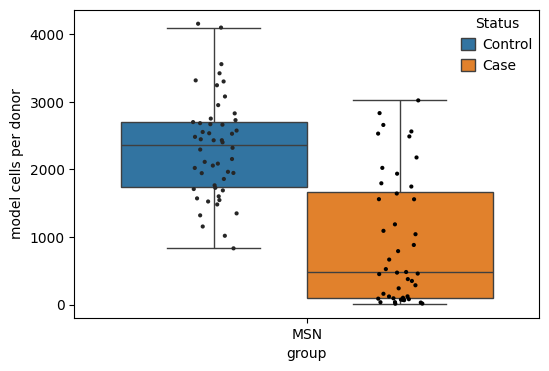

donors     sum  median
group Status                         
MSN   Control      50  115597  2360.5
      Case         44   40968   478.5

In [5]:
model_obs = obs[obs["in_model"]]
if RESPONSE_TYPE == "numeric":
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=model_obs, x=DONOR_COL, y=RESPONSE, hue="group", showfliers=False)
    plt.xticks(rotation=45)
    plt.savefig(f"{OUT_DIR}/response_by_donor.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    # cells per donor in each level: the levels should not differ much
    per_donor = model_obs.groupby(["group", RESPONSE, DONOR_COL], observed=True).size().rename("cells").reset_index()
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=per_donor, x="group", y="cells", hue=RESPONSE, showfliers=False)
    sns.stripplot(data=per_donor, x="group", y="cells", hue=RESPONSE, dodge=True, size=3, color="black", legend=False)
    plt.ylabel("model cells per donor")
    plt.savefig(f"{OUT_DIR}/cells_per_donor.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(per_donor.groupby(["group", RESPONSE], observed=True)["cells"].agg(["count", "sum", "median"]).rename(columns={"count": "donors"}))

# Factors
Each group has its own factors (PC_1 of Matrix and PC_1 of Patch are different axes). `factor_names[group]` = the factors of the group; their scores go into `adata.obs`. Only the cell of the chosen `FACTOR_METHOD` does something.

### PCA
One PCA per group, from BICAN (loaded) or from the Control cells of this dataset (fitted here). Every cell of the group is projected onto it with `reference_pca.project_pca`: same normalisation, same HVGs, z-scored with the reference mean / SD, × loadings.

In [6]:
factor_names, scores = {}, []

if FACTOR_METHOD == "pca":
    pcas = {}
    for group in groups:
        if FACTORS_FROM == "bican":
            print("From Bican")
            pcas[group] = sc.read_h5ad(f"{BICAN_PCA_DIR}/{group}.h5ad")
        elif FACTORS_FROM == "healthy_samples":
            print("Fit PCA to new")
            # Control cells of the group, all donors (also those not in the model, e.g. Age >89)
            healthy = adata[((adata.obs["group"] == group) & (adata.obs["Status"] == "Control")).values].copy()
            sc.pp.filter_genes(healthy, min_cells=MIN_CELLS_PER_GENE_REF)
            pcas[group] = reference_pca.fit_pca(healthy, n_hvg=N_HVG, n_pcs=N_PCS, target_sum=TARGET_SUM, seed=SEED)
        print(f"{group}: PCA from {pcas[group].n_obs} {FACTORS_FROM} cells, {pcas[group].var['highly_variable'].sum()} HVGs")

        # genes: the BICAN PCA uses gene names, with Ensembl IDs in var["gene_id"]; VILLAGE var_names are Ensembl IDs
        match_on = "gene_id" if FACTORS_FROM == "bican" else None
        s = reference_pca.project_pca(adata[(adata.obs["group"] == group).values], pcas[group], match_on=match_on)
        factor_names[group] = list(s.columns)
        scores.append(s)

From Bican
MSN: PCA from 112920 bican cells, 3000 HVGs
  31114/35957 PCA genes found, 2640/3000 HVGs


### cNMF
Spectra are trained outside this notebook (e.g. on UGER) on the reference counts. A group without a spectra file in `CNMF_SPECTRA` gets its reference counts written (healthy_samples), and the notebook stops. With spectra, each cell's usage is the non-negative least-squares fit of its counts (each gene divided by its SD in the reference counts) on the spectra, as in `nebula_with_factors`.

In [7]:
# if FACTOR_METHOD == "cnmf":
#     for group in groups:
#         # reference counts, with Ensembl IDs as var_names (as HD)
#         if FACTORS_FROM == "bican":
#             ref = sc.read_h5ad(f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad")          # BICAN gene names, IDs in var["gene_id"]
#             name_to_id = dict(zip(ref.var_names, ref.var["gene_id"]))
#             ref = ref[:, (ref.var["gene_id"] != "").values & ~ref.var["gene_id"].duplicated(keep=False).values].copy()
#             ref.var_names = ref.var["gene_id"].values
#         elif FACTORS_FROM == "healthy_samples":
#             ref = adata[((adata.obs["group"] == group) & (adata.obs["Status"] == "Control")).values].copy()
#             name_to_id = None

#         if group not in CNMF_SPECTRA:
#             if FACTORS_FROM == "healthy_samples":
#                 path = f"{OUT_DIR}/{group}/cnmf_input.h5ad"
#                 os.makedirs(os.path.dirname(path), exist_ok=True)
#                 ad.AnnData(ref.X.astype(np.float64), obs=ref.obs[[DONOR_COL]], var=ref.var[["gene_name"]]).write_h5ad(path)   # cNMF needs float64 counts
#             else:
#                 path = f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad"
#             raise RuntimeError(f"no cNMF spectra for {group}: train cNMF on {path}, then add CNMF_SPECTRA['{group}']")

#         spectra = pd.read_csv(CNMF_SPECTRA[group], sep="\t", index_col=0)         # GEPs x genes
#         spectra.index = [f"GEP_{i + 1}" for i in range(len(spectra))]
#         if name_to_id is not None:
#             spectra.columns = [name_to_id.get(g, "") for g in spectra.columns]
#             spectra = spectra.loc[:, spectra.columns != ""]

#         print(f"{group}: cNMF {len(spectra)} GEPs, reference {ref.n_obs} {FACTORS_FROM} cells")
#         s = reference_pca.cnmf_usage(adata[(adata.obs["group"] == group).values], spectra, ref, normalise=CNMF_NORMALISE)
#         if CNMF_NORMALISE:
#             s = s.iloc[:, :-1]                    # fractions sum to 1: the last GEP is redundant
#         factor_names[group] = list(s.columns)
#         scores.append(s)

### DV score
Genes whose dorsal–ventral spatial gradient in BICAN is strong **and** agrees in sign in health and XDP (disease-invariant spatial markers), weight = mean ρ of the two. Each cell's score = z-scored log-normalised expression of these genes (within the group) × weights. The columns used for each group are `DV_GRADIENT_CT[group]`.

In [8]:
if FACTOR_METHOD == "dv_score":
    df_corr_health = pd.read_csv(f"{DV_CORR_DIR}/df_corr.csv", index_col=0)
    df_corr_xdp = pd.read_csv(f"{DV_CORR_DIR}/df_corr_xdp.csv", index_col=0)
    common_genes = df_corr_health.index.intersection(df_corr_xdp.index)
    dfh, dfx = df_corr_health.loc[common_genes], df_corr_xdp.loc[common_genes]

    # gene names -> VILLAGE Ensembl IDs (names used by several IDs are left out)
    names = adata.var["gene_name"]
    name_to_id = dict(zip(names[~names.duplicated(keep=False)], names[~names.duplicated(keep=False)].index))

    for group in groups:
        ct = DV_GRADIENT_CT[group]
        reliable = pd.Series(True, index=common_genes)
        for d in [dfh, dfx]:
            reliable &= (d[f"rho_{ct}"].abs() >= DV_MIN_ABS_RHO) & (d[f"padj_{ct}"] < DV_PADJ)
            reliable &= (d[f"pct_expr_{ct}"] >= DV_MIN_PCT_EXPR) & (d[f"mean_expr_{ct}"] >= DV_MIN_MEAN_EXPR)
        stable = reliable & (np.sign(dfh[f"rho_{ct}"]) == np.sign(dfx[f"rho_{ct}"]))
        weights = (dfh.loc[stable, f"rho_{ct}"] + dfx.loc[stable, f"rho_{ct}"]) / 2
        weights.index = [name_to_id.get(g, "") for g in weights.index]
        weights = weights[weights.index != ""]

        print(f"{group}: {stable.sum()} stable gradient genes ({ct})")
        s = reference_pca.gradient_score(adata[(adata.obs["group"] == group).values], weights, target_sum=TARGET_SUM)
        factor_names[group] = ["dv_score"]
        scores.append(s.to_frame("dv_score"))

In [9]:
if FACTOR_METHOD != "none":
    scores = pd.concat(scores)
    adata.obs = adata.obs.drop(columns=scores.columns, errors="ignore").join(scores)
    display(adata.obs[["group", *scores.columns[:5]]].head())

,group,PC_1,PC_2,PC_3,PC_4,PC_5
Village14_rxn1_CTCACTGAGGGCTTCC,MSN,-1.852581,2.256195,-8.257574,9.605683,-1.016577
Village14_rxn1_AATCGACCATCTCCCA,MSN,-2.707296,-10.212886,-3.891279,8.963070,3.883237
Village14_rxn1_TCGACCTTCTGCTTTA,MSN,1.340493,-0.258512,-7.806288,2.417757,6.074383
Village14_rxn1_CACTGAACAGCTGTTA,MSN,-4.716754,4.610349,-11.784048,-1.361337,1.704679
Village14_rxn1_CCTGCATTCGCCGTGA,MSN,3.489271,6.326209,-7.579088,1.718602,6.747078


### Scree plot and knee (PCA only)

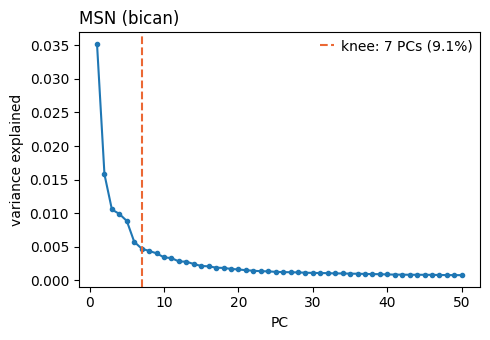

MSN: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7']


In [10]:
n_knee = {}
if FACTOR_METHOD == "pca":
    fig, axes = plt.subplots(1, len(pcas), figsize=(5 * len(pcas), 3.5), squeeze=False)
    for ax, (group, pca) in zip(axes[0], pcas.items()):
        evr = pca.uns["variance_ratio"]
        n_knee[group] = reference_pca.knee_point(evr)
        ax.plot(np.arange(1, len(evr) + 1), evr, "o-", ms=3)
        ax.axvline(n_knee[group], color="#eb6834", ls="--", label=f"knee: {n_knee[group]} PCs ({evr[:n_knee[group]].sum():.1%})")
        ax.set_xlabel("PC")
        ax.set_ylabel("variance explained")
        ax.set_title(f"{group} ({FACTORS_FROM})", loc="left")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/scree.png", dpi=150)
    plt.show()

# factors that can enter the model: PC_1 ... knee, or all GEPs / the DV score
candidates = {}
for group in groups:
    if FACTOR_METHOD == "pca":
        candidates[group] = factor_names[group][:n_knee[group]]
    else:
        candidates[group] = factor_names.get(group, [])
    print(f"{group}: candidate factors {candidates[group]}")

### Are the factors associated with the response?
For each factor, on the model cells of the group: `scale(factor) ~ RESPONSE + covariates + (1 | DONOR)`. `beta` = factor SDs per unit of the response (or tested vs baseline). "Associated" = FDR < `ASSOC_FDR` **and** |beta| ≥ `ASSOC_MIN_ABS_BETA` (with thousands of cells nearly every factor is significant).

An associated factor is either a **confounder** (adjusting is right) or is **moved by the response** (adjusting removes real signal): the data cannot tell the two apart. `FACTOR_ASSOCIATION` decides what to do with them; compare the factor model with the baseline.

`candidate` = the factor can enter the model (PCA: up to the knee). `var_ratio` (PCA) = variance of the PC in the model cells / in the reference: much less than 1 means the axis barely varies here.

MSN: candidate factors associated with Status: ['PC_2', 'PC_5']


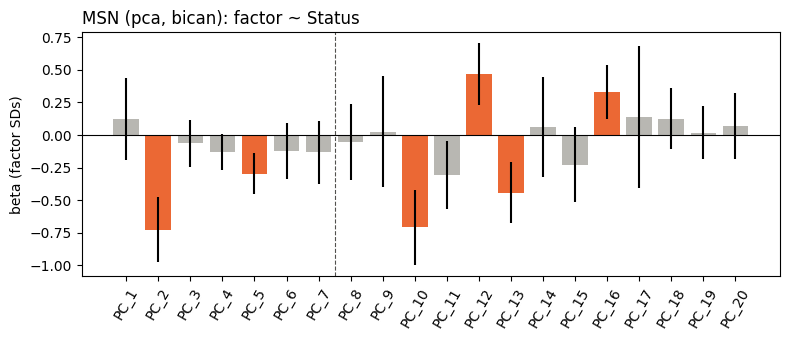

MSN                                                    
         beta     se      p candidate var_ratio    fdr associated
factor                                                           
PC_1    0.124  0.159  0.438      True     0.286  0.673      False
PC_2   -0.727  0.127  0.000      True     0.777  0.000       True
PC_3   -0.064  0.092  0.491      True     0.577  0.702      False
PC_4   -0.130  0.072  0.072      True     0.725  0.181      False
PC_5   -0.296  0.079  0.000      True     0.779  0.001       True
PC_6   -0.123  0.108  0.255      True     0.628  0.489      False
PC_7   -0.131  0.123  0.286      True     0.975  0.489      False
PC_8   -0.054  0.149  0.714     False     0.515  0.829      False
PC_9    0.026  0.217  0.905     False     0.607  0.905      False
PC_10  -0.709  0.147  0.000     False     1.230  0.000       True
PC_11  -0.308  0.134  0.022     False     1.432  0.062      False
PC_12   0.467  0.121  0.000     False     0.732  0.001       True
PC_13  -0.443  0.119  0.000     False     1.673  0.001       True
PC_14   0.063  0.195  0.746     False     0.791  0.829      False
PC_15  -0.226  0.146  0.122     False     1.530  0.271      False
PC_16   0.330  0.107  0.002     False     0.822  0.007       True
PC_17   0.136  0.278  0.623     False     0.598  0.779      False
PC_18   0.127  0.120  0.293     False     1.013  0.489      False
PC_19   0.019  0.103  0.854     False     1.561  0.899      False
PC_20   0.071  0.130  0.586     False     1.271  0.779      False

In [11]:
# name of the tested term in statsmodels
response_param = RESPONSE if RESPONSE_TYPE == "numeric" else f"{RESPONSE}[T.{RESPONSE_TESTED}]"

assoc = {}
if FACTOR_METHOD != "none":
    for group in groups:
        cells = adata.obs[adata.obs["in_model"] & (adata.obs["group"] == group)].copy()
        to_test = factor_names[group]
        if FACTOR_METHOD == "pca":
            to_test = to_test[:max(N_PCS_TO_TEST, n_knee[group])]

        rows = []
        for i, f in enumerate(to_test):
            cells["y"] = (cells[f] - cells[f].mean()) / cells[f].std()
            formula = "y ~ " + " + ".join([RESPONSE, *covariates[group]])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(formula, cells, groups=cells[DONOR_COL]).fit()
            row = {"factor": f, "beta": fit.params[response_param], "se": fit.bse[response_param],
                   "p": fit.pvalues[response_param], "candidate": f in candidates[group]}
            if FACTOR_METHOD == "pca":
                row["var_ratio"] = cells[f].var() / pcas[group].obsm["X_pca"][:, i].var()
            rows.append(row)

        a = pd.DataFrame(rows).set_index("factor")
        a["fdr"] = multipletests(a["p"], method="fdr_bh")[1]
        a["associated"] = (a["fdr"] < ASSOC_FDR) & (a["beta"].abs() >= ASSOC_MIN_ABS_BETA)
        a.to_csv(f"{OUT_DIR}/{group}_factor_association.csv")
        assoc[group] = a
        print(f"{group}: candidate factors associated with {RESPONSE}: {a.index[a['candidate'] & a['associated']].tolist()}")

    # beta with 95% CI; orange = associated; dashed line = end of the candidates (PCA: knee)
    fig, axes = plt.subplots(1, len(assoc), figsize=(max(6, 0.4 * len(a)) * len(assoc), 3.5), squeeze=False)
    for ax, (group, a) in zip(axes[0], assoc.items()):
        ax.bar(a.index, a["beta"], yerr=1.96 * a["se"], color=np.where(a["associated"], "#eb6834", "#b8b7b2"))
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(a["candidate"].sum() - 0.5, color="#52514e", ls="--", lw=0.8)
        ax.set_ylabel("beta (factor SDs)")
        ax.set_title(f"{group} ({FACTOR_METHOD}, {FACTORS_FROM}): factor ~ {RESPONSE}", loc="left")
        ax.tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/factor_association.png", dpi=150)
    plt.show()

pd.concat(assoc, axis=1).round(3) if assoc else None

# Models
`baseline` has no factors. The factor model has the candidate factors, filtered by `FACTOR_ASSOCIATION`.

In [12]:
factor_model_name = {"pca": "pca_knee", "cnmf": "cnmf", "dv_score": "dv_score"}.get(FACTOR_METHOD)
if FACTOR_ASSOCIATION != "all":
    factor_model_name += f"_{FACTOR_ASSOCIATION}"

models = {}
for group in groups:
    models[group] = {"baseline": []}
    if FACTOR_METHOD != "none":
        chosen = candidates[group]
        if FACTOR_ASSOCIATION == "only_associated":
            chosen = [f for f in chosen if assoc[group].loc[f, "associated"]]
        elif FACTOR_ASSOCIATION == "drop_associated":
            chosen = [f for f in chosen if not assoc[group].loc[f, "associated"]]
        models[group][factor_model_name] = chosen

    for name, factors in models[group].items():
        print(f"{group} / {name}: counts ~ {' + '.join([RESPONSE, *covariates[group], *factors])} + (1|{DONOR_COL})")

MSN / baseline: counts ~ Status + Age + Sex + pct_counts_mt + msn_subtype + village + (1|DONOR)
MSN / pca_knee: counts ~ Status + Age + Sex + pct_counts_mt + msn_subtype + village + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + (1|DONOR)


# Genes tested and design
Per group, on its model cells: a gene is tested if detected in ≥ n_donors × `MIN_CELLS_PER_DONOR` cells **and** ≥ `MIN_COUNTS_PER_GENE` counts. Handsaker phase genes (`FORCE_KEEP_PHASES`) are tested anyway if detected in ≥ 1 cell: their estimates can be unreliable, check `forced_gene` and `n_cells_detected` in the results.

Columns in `STANDARDISE` (and the factors, if `STANDARDISE_FACTORS`) are z-scored over the model cells: only their own coefficients change, not the tested one.

In [13]:
force_keep_genes = []
for phase in FORCE_KEEP_PHASES:
    force_keep_genes += pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"].tolist()

m, gene_table = {}, {}
for group in groups:
    mc = adata[(adata.obs["in_model"] & (adata.obs["group"] == group)).values].copy()
    factors = factor_names.get(group, [])

    # genes
    min_cells = mc.obs[DONOR_COL].nunique() * MIN_CELLS_PER_DONOR
    g = pd.DataFrame({
        "gene_name": mc.var["gene_name"],
        "n_cells_detected": np.asarray((mc.X > 0).sum(axis=0)).ravel(),
        "total_counts": np.asarray(mc.X.sum(axis=0)).ravel(),
    })
    passes = (g["n_cells_detected"] >= min_cells) & (g["total_counts"] >= MIN_COUNTS_PER_GENE)
    g["forced_gene"] = ~passes & g["gene_name"].isin(force_keep_genes) & (g["n_cells_detected"] >= 1)
    g = g[passes | g["forced_gene"]]
    print(f"{group}: {passes.sum()} genes pass the filter + {g['forced_gene'].sum()} forced = {len(g)} tested")

    # design
    for c in covariates[group]:
        if COVARIATES[c] == "categorical":
            mc.obs[c] = mc.obs[c].astype(str)
    to_standardise = [c for c in STANDARDISE if c in covariates[group]] + (factors if STANDARDISE_FACTORS else [])
    for c in to_standardise:
        mc.obs[c] = (mc.obs[c] - mc.obs[c].mean()) / mc.obs[c].std()

    m[group] = mc[:, g.index].copy()
    gene_table[group] = g
    os.makedirs(f"{OUT_DIR}/{group}", exist_ok=True)
    g.to_csv(f"{OUT_DIR}/{group}/genes_tested.csv")
    mc.obs[[DONOR_COL, LIBRARY_SIZE_COL, RESPONSE, *covariates[group], *factors]].to_csv(f"{OUT_DIR}/{group}/design_table.csv")

MSN: 22159 genes pass the filter + 107 forced = 22266 tested


# NEBULA
For each group and model. `nebula_runner.finalise` adds gene names, `log2FC_<coef>` (NEBULA reports natural log), `converged` (convergence code 1) and the BH FDR over the converged genes.

In [14]:
results = {}
for group in groups:
    results[group] = {}
    for name, factors in models[group].items():
        print(f"\n######## {group} / {name}")
        terms = [RESPONSE, *covariates[group], *factors]
        types = {RESPONSE: RESPONSE_TYPE, **{c: COVARIATES[c] for c in covariates[group]}, **{f: "numeric" for f in factors}}

        raw = nebula_runner.run(m[group], terms, types, donor_col=DONOR_COL, offset_col=LIBRARY_SIZE_COL,
                                method=NEBULA_METHOD, n_folds=N_FOLDS, n_cores=N_CORES,
                                cpc=NEBULA_CPC, mincp=NEBULA_MINCP, tmp_dir=f"{OUT_DIR}/tmp")
        res = nebula_runner.finalise(raw, gene_table[group], coef=coef, convergence_ok=[1], fdr=FDR)

        os.makedirs(f"{OUT_DIR}/{group}/{name}", exist_ok=True)
        res.to_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv", index=False)
        results[group][name] = res


######## MSN / baseline
NEBULA-LN: 22266 genes x 156565 cells, 94 donors, 40 chunks on 40 cores; formula ~ Status + Age + Sex + pct_counts_mt + msn_subtype + village + (1|DONOR), offset total_counts
  4/40 chunks done
  8/40 chunks done
  12/40 chunks done
  16/40 chunks done
  20/40 chunks done
  24/40 chunks done
  28/40 chunks done
  32/40 chunks done
  36/40 chunks done
  40/40 chunks done
  22266 genes fitted (0 removed by NEBULA cpc/mincp), 21707 converged; 9198 with FDR < 0.05

######## MSN / pca_knee
NEBULA-LN: 22266 genes x 156565 cells, 94 donors, 40 chunks on 40 cores; formula ~ Status + Age + Sex + pct_counts_mt + msn_subtype + village + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + (1|DONOR), offset total_counts
  4/40 chunks done
  8/40 chunks done
  12/40 chunks done
  16/40 chunks done
  20/40 chunks done
  24/40 chunks done
  28/40 chunks done
  32/40 chunks done
  36/40 chunks done
  40/40 chunks done
  22266 genes fitted (0 removed by NEBULA cpc/mincp), 21657 con

In [15]:
# # results of an earlier run, without fitting again (run this instead of the cell above)
# results = {group: {name: pd.read_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv") for name in models[group]}
#            for group in groups}

# Results

In [16]:
LFC = f"log2FC_{coef}"
P = f"p_{coef}"
P_ADJ = f"fdr_{coef}"

summary = []
for group in results:
    for name, r in results[group].items():
        sig = r[P_ADJ] < FDR
        summary.append({"group": group, "model": name, "n_factors": len(models[group][name]), "genes": len(r),
                        "converged": r["converged"].sum(), f"FDR < {FDR}": sig.sum(),
                        "up": (sig & (r[LFC] > 0)).sum(), "down": (sig & (r[LFC] < 0)).sum()})
summary = pd.DataFrame(summary)
summary.to_csv(f"{OUT_DIR}/summary_n_degs.csv", index=False)
summary

,group,model,n_factors,genes,converged,FDR < 0.05,up,down
0,MSN,baseline,0,22266,21707,9198,2736,6462
1,MSN,pca_knee,7,22266,21657,6312,1526,4786


### Factor model vs baseline
Converged genes. Blue = significant in both, orange = baseline only, green = factor model only. Points below the diagonal: the factors absorb part of the effect.

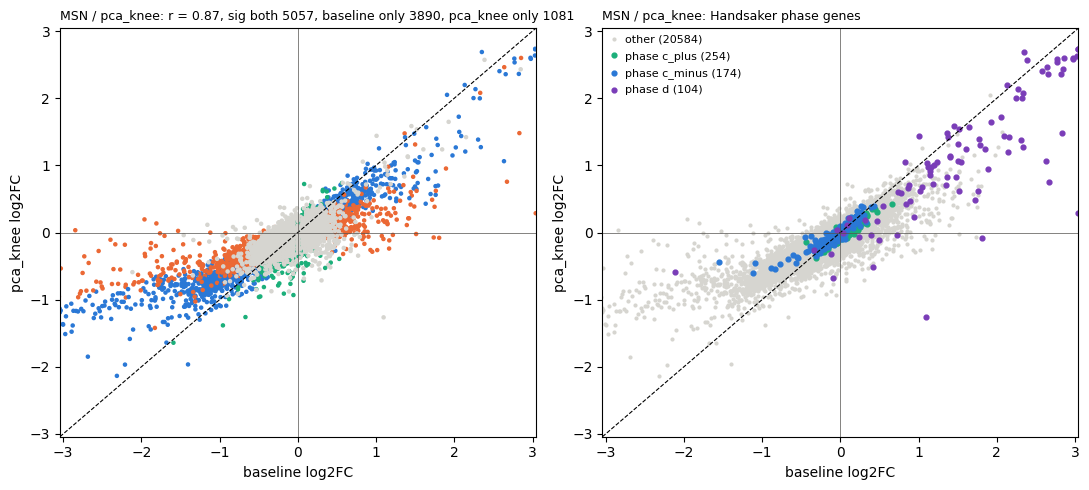

In [17]:
# Handsaker phase genes (gene names)
phase_colors = {"c_plus": "#1baf7a", "c_minus": "#2a78d6", "d": "#7a3db8"}
phase_genes = {phase: pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"] for phase in phase_colors}

for group in results:
    other = [name for name in results[group] if name != "baseline"]
    if not other:
        continue
    # one row per factor model: left = coloured by significance, right = coloured by Handsaker phase
    fig, axes = plt.subplots(len(other), 2, figsize=(11, 5 * len(other)), squeeze=False)
    for (ax1, ax2), name in zip(axes, other):
        both = results[group]["baseline"].merge(results[group][name], on="gene_id", suffixes=("_base", "_model"))
        both = both[both["converged_base"] & both["converged_model"]]
        x, y = both[f"{LFC}_base"], both[f"{LFC}_model"]
        sig_base, sig_model = both[f"{P_ADJ}_base"] < FDR, both[f"{P_ADJ}_model"] < FDR
        lim = pd.concat([x, y]).abs().quantile(0.999)
        r = np.corrcoef(x, y)[0, 1]

        # significance
        color = np.select([sig_base & sig_model, sig_base, sig_model], ["#2a78d6", "#eb6834", "#1baf7a"], "#d6d5d0")
        ax1.scatter(x, y, s=5, c=color)
        ax1.set_title(f"{group} / {name}: r = {r:.2f}, sig both {(sig_base & sig_model).sum()}, "
                      f"baseline only {(sig_base & ~sig_model).sum()}, {name} only {(~sig_base & sig_model).sum()}", fontsize=9, loc="left")

        # Handsaker phase: other genes grey, phase genes on top
        in_any = both["gene_name_base"].isin(pd.concat(phase_genes.values()))
        ax2.scatter(x[~in_any], y[~in_any], s=4, c="#d6d5d0", label=f"other ({(~in_any).sum()})")
        for phase, col in phase_colors.items():
            in_phase = both["gene_name_base"].isin(phase_genes[phase])
            ax2.scatter(x[in_phase], y[in_phase], s=12, c=col, label=f"phase {phase} ({in_phase.sum()})")
        ax2.legend(fontsize=8, loc="upper left")
        ax2.set_title(f"{group} / {name}: Handsaker phase genes", fontsize=9, loc="left")

        for ax in (ax1, ax2):
            ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
            ax.axhline(0, color="#52514e", lw=0.5)
            ax.axvline(0, color="#52514e", lw=0.5)
            ax.set_xlim(-lim, lim)
            ax.set_ylim(-lim, lim)
            ax.set_xlabel("baseline log2FC")
            ax.set_ylabel(f"{name} log2FC")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_models_vs_baseline.png", dpi=150)
    plt.show()


### Volcano plots with gene sets
Per group, one row per model: Handsaker phase genes, healthy dorsal–ventral gradient of each gene (`mean_spearman`, red / blue = up / down along the gradient), top genes. |log2FC| above `MAX_X` is drawn at the edge.

2026-11-05 19:45:53 | [WARNING] Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.
/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


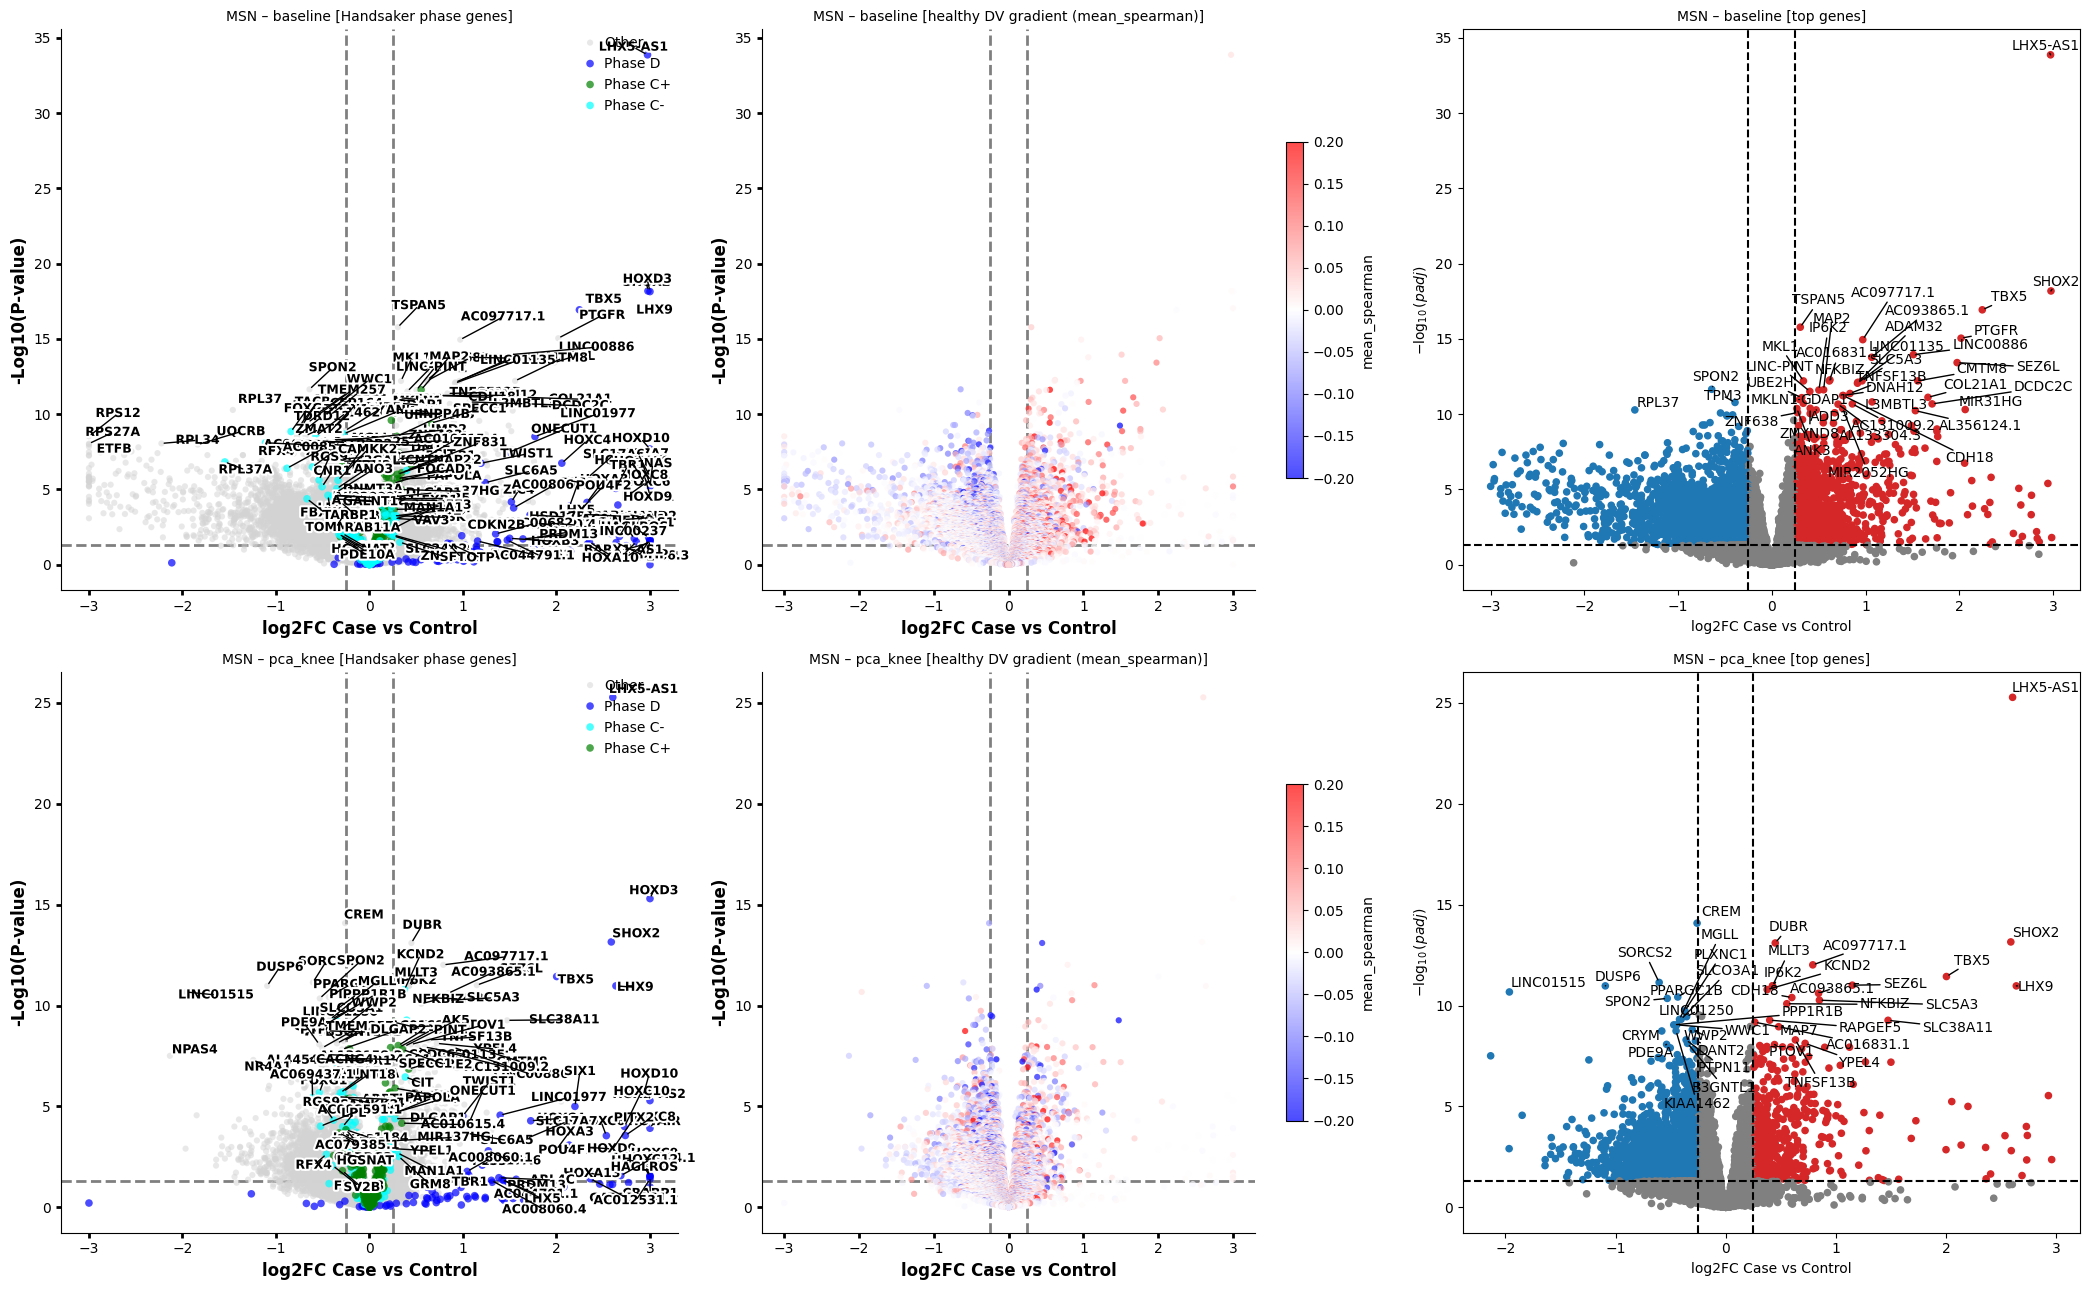

In [18]:
# Handsaker phase genes and healthy dorsal-ventral gradient

phase_colors = {"c_plus": "#1baf7a", "c_minus": "#2a78d6", "d": "#7a3db8"}
phase_genes = {phase: pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"] for phase in phase_colors}
x_label = f"log2FC per unit of {RESPONSE}" if RESPONSE_TYPE == "numeric" else f"log2FC {RESPONSE_TESTED} vs {RESPONSE_BASELINE}"

categories_handsaker_phases = {
    "Phase D":  (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_d_genes.csv")["Gene"].tolist(), "blue"),
    "Phase C+": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_plus_genes.csv")["Gene"].tolist(), "green"),
    "Phase C-": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_minus_genes.csv")["Gene"].tolist(), "cyan"),
}
df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv").set_index("gene")

for group in results:
    fig, axes = plt.subplots(len(results[group]), 3, figsize=(21, 6.5 * len(results[group])), squeeze=False)

    for row, (name, r) in zip(axes, results[group].items()):
        # converged genes, with the healthy gradient of each gene; log2FC clipped at MAX_X
        df = r[r["converged"]].merge(df_grad[["mean_spearman"]], how="left", left_on="gene_name", right_index=True)
        df_plot = df.assign(**{LFC: df[LFC].clip(-MAX_X, MAX_X)})
        ax1, ax2, ax3 = row

        DEG.plot_vulcano(df_plot, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=30,
                         categories=categories_handsaker_phases, max_y=None, ax=ax1, print_labels=True)
        DEG.plot_vulcano(df_plot, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=0,
                         color_by="mean_spearman", cmap="bwr", vmin=-0.2, vmax=0.2,
                         max_y=None, ax=ax2, print_labels=False)
        # top genes labelled (gene names can repeat across Ensembl IDs: keep the most significant)
        top = df.sort_values(P_ADJ).drop_duplicates("gene_name").set_index("gene_name")
        dc.pl.volcano(top.rename(columns={P_ADJ: "padj", LFC: "logFC"}),
                      x="logFC", y="padj", top=40, thr_stat=LOGFC_THR, thr_sign=FDR, max_stat=MAX_X, ax=ax3)

        for ax, lbl in zip(row, ["Handsaker phase genes", "healthy DV gradient (mean_spearman)", "top genes"]):
            ax.set_title(f"{group} – {name} [{lbl}]", fontsize=10)
            ax.set_xlabel(x_label)

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_volcano_all_models.png", dpi=150, bbox_inches="tight")
    plt.show()

### Factor model vs baseline: how much of the effect goes through the factors
For each gene, the baseline effect splits into the effect at a fixed factor value plus a part through the factors:

```
log2FC_baseline  ≈  log2FC_model  +  sum_k log2FC_factor_k(gene) * delta_k
```

`delta_k` = shift of factor k (as in the NEBULA design) between `RESPONSE_TESTED` and `RESPONSE_BASELINE` (numeric: per unit of the response), from the LMM `factor_k ~ response + covariates + (1|donor)` on the design table of the group.
* `log2FC_model` = response effect at fixed position on the factors.
* `sum_k log2FC_factor_k * delta_k` = positional component: confounding (e.g. Case donors with different cell composition along the factor) OR a disease effect that moves cells along the factors. The data cannot separate the two.

`corr(baseline - adjusted, positional component)` should be close to 1: otherwise the decomposition does not hold well for that model.

In [19]:
phase_of_gene = {g: label for phase, label in [("c_plus", "C+"), ("c_minus", "C-"), ("d", "D")]
                 for g in pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"]}

decomp = {}
for group in results:
    design = pd.read_csv(f"{OUT_DIR}/{group}/design_table.csv", index_col=0)
    if RESPONSE_TYPE == "categorical":
        design[RESPONSE] = pd.Categorical(design[RESPONSE].astype(str), categories=[RESPONSE_BASELINE, RESPONSE_TESTED])
    rhs = " + ".join([RESPONSE, *covariates[group]])
    base = results[group]["baseline"].set_index("gene_id")

    for name, factors in models[group].items():
        if name == "baseline" or not factors:
            continue
        model = results[group][name].set_index("gene_id")

        # delta_k of each factor
        delta = {}
        for f in factors:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(f"{f} ~ {rhs}", design, groups=design[DONOR_COL]).fit(reml=True)
            delta[f] = {"delta": fit.params[response_param], "p": fit.pvalues[response_param]}

        # genes converged in both models
        g = base.index[base["converged"]].intersection(model.index[model["converged"]])
        d = pd.DataFrame({
            "gene_name": model.loc[g, "gene_name"],
            "logFC_baseline": base.loc[g, LFC],
            "logFC_adjusted": model.loc[g, LFC],
            "positional_component": sum(model.loc[g, f"log2FC_{f}"] * delta[f]["delta"] for f in factors),
            "sig_baseline": base.loc[g, P_ADJ] < FDR,
            "sig_adjusted": model.loc[g, P_ADJ] < FDR,
            "n_cells_detected": model.loc[g, "n_cells_detected"],
        })
        d["mean_spearman"] = d["gene_name"].map(df_grad["mean_spearman"])
        d["phase"] = d["gene_name"].map(phase_of_gene).fillna("")
        only = f"revealed by adjustment ({name} only)"
        d["category"] = np.select(
            [d.sig_baseline & d.sig_adjusted & (np.sign(d.logFC_baseline) == np.sign(d.logFC_adjusted)),
             d.sig_baseline & ~d.sig_adjusted,
             ~d.sig_baseline & d.sig_adjusted],
            ["robust (both)", "position-dependent (baseline only)", only],
            "not significant")
        decomp[(group, name)] = d
        d.to_csv(f"{OUT_DIR}/{group}/{name}/response_effect_position_decomposition.csv")

        check = np.corrcoef(d.logFC_baseline - d.logFC_adjusted, d.positional_component)[0, 1]
        print(f"\n######## {group} / {name}: {len(factors)} factors; corr(baseline - adjusted, positional component) = {check:.2f}")
        display(pd.DataFrame(delta).T.rename(columns={"delta": "delta (factor units)"}).round(4))
        display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))


######## MSN / pca_knee: 7 factors; corr(baseline - adjusted, positional component) = 0.93


,delta (factor units),p
PC_1,0.1235,0.4375
PC_2,-0.7272,0.0000
PC_3,-0.0636,0.4914
PC_4,-0.1299,0.0722
PC_5,-0.2961,0.0002
PC_6,-0.1230,0.2552
PC_7,-0.1314,0.2857


phase,C+,C-,D,other,All
category,,,,,
not significant,89,58,43,10900,11090
position-dependent (baseline only),61,19,20,3790,3890
revealed by adjustment (pca_knee only),27,12,1,1041,1081
robust (both),77,85,40,4853,5055
All,254,174,104,20584,21116


In [20]:
for (group, name), d in decomp.items():
    print(f"\n######## {group} / {name}")
    for cat in ["robust (both)", "position-dependent (baseline only)", f"revealed by adjustment ({name} only)"]:
        top = d[d["category"] == cat]
        top = top.reindex(top["logFC_baseline"].abs().sort_values(ascending=False).index)
        print(f"{cat}: {len(top)} genes")
        display(top.head(50)[["gene_name", "logFC_baseline", "logFC_adjusted", "positional_component",
                              "mean_spearman", "phase", "n_cells_detected"]].round(3))


######## MSN / pca_knee
robust (both): 5055 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000180806,HOXC9,5.922,5.474,0.536,0.008,D,153
ENSG00000128652,HOXD3,4.714,4.371,0.304,0.002,D,621
ENSG00000260597,AC012531.1,4.363,4.157,0.633,0.010,D,24
ENSG00000166426,CRABP1,4.325,5.956,0.217,0.012,D,12
ENSG00000104888,SLC17A7,3.922,1.683,1.174,0.036,D,168
ENSG00000112306,RPS12,-3.789,-1.590,-1.298,0.017,,27892
ENSG00000228630,HOTAIR,3.515,3.476,0.024,-0.005,D,131
ENSG00000128710,HOXD10,3.472,2.928,0.448,-0.001,D,439
ENSG00000198755,RPL10A,-3.462,-1.428,-0.916,0.038,,15215


position-dependent (baseline only): 3890 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000235601,BARX1-AS1,3.890,3.287,1.014,NaN,D,33
ENSG00000229117,RPL41,-3.613,-0.906,-1.170,0.038,,5937
ENSG00000105193,RPS16,-3.363,-0.707,-1.020,-0.013,,4157
ENSG00000236536,AC003986.3,3.174,2.771,0.795,-0.006,D,45
ENSG00000197728,RPS26,-3.120,-1.032,-1.078,-0.002,,11413
ENSG00000110700,RPS13,-3.108,-0.965,-1.234,-0.007,,13480
ENSG00000149806,FAU,-3.072,-0.968,-1.171,-0.021,,25995
ENSG00000145425,RPS3A,-3.054,-0.954,-1.134,0.030,,8447
ENSG00000087460,GNAS,3.041,0.287,1.708,0.117,D,547


revealed by adjustment (pca_knee only): 1081 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000258952,SALRNA1,2.746,3.505,-0.290,0.003,D,37
ENSG00000099860,GADD45B,-1.590,-1.641,0.319,-0.025,,1060
ENSG00000164949,GEM,-0.957,-1.383,0.689,0.028,,1317
ENSG00000253444,AC245519.1,-0.879,-0.992,-0.042,-0.028,,2521
ENSG00000177105,RHOG,-0.765,-0.847,0.111,-0.001,,2005
ENSG00000138646,HERC5,-0.761,-0.816,-0.049,0.022,,2606
ENSG00000198695,MT-ND6,-0.669,-1.259,0.703,-0.013,,2872
ENSG00000270087,AC010997.3,-0.571,-0.710,0.141,0.041,,68060
ENSG00000004846,ABCB5,0.564,0.737,-0.202,-0.006,,2551


# PCs BICAN Vs PCs Helthy

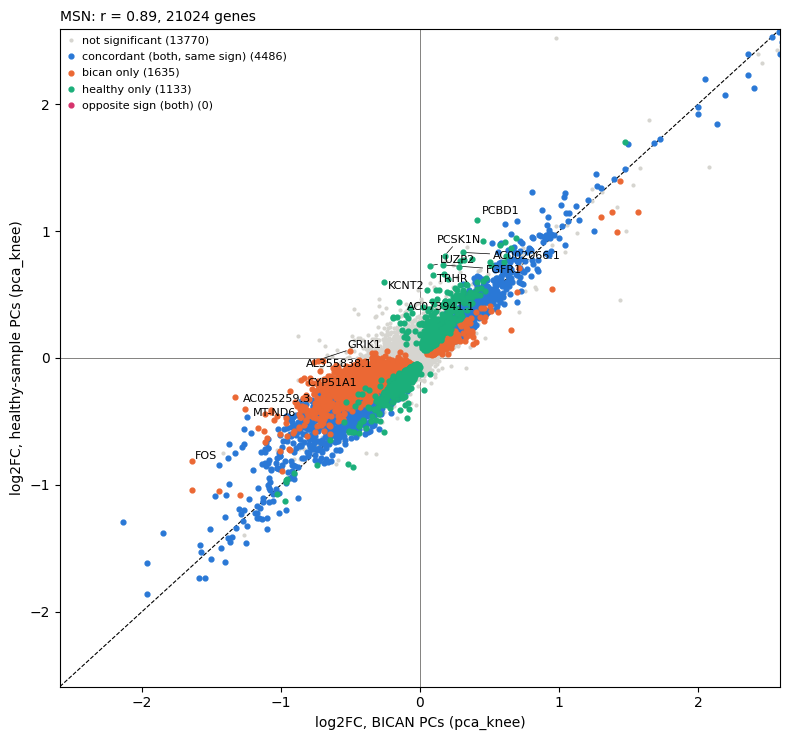


######## MSN


phase,C+,C-,D,other,All
category,,,,,
bican only,18,9,10,1598,1635
"concordant (both, same sign)",86,83,31,4286,4486
healthy only,16,17,2,1098,1133
not significant,136,63,60,13511,13770
All,256,172,103,20493,21024


concordant (both, same sign): 4486 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000180806,HOXC9,5.474,5.402,0.003,0.003,D,153,True
ENSG00000128652,HOXD3,4.371,4.529,0.000,0.000,D,621,True
ENSG00000228630,HOTAIR,3.476,3.733,0.000,0.000,D,131,True
ENSG00000225231,LINC02470,3.381,3.019,0.019,0.033,,1720,False
ENSG00000237380,HOXD-AS2,3.200,2.871,0.000,0.000,D,215,True
ENSG00000259203,AC016044.1,2.957,2.800,0.004,0.007,D,75,True
ENSG00000128710,HOXD10,2.928,2.888,0.000,0.000,D,439,True
ENSG00000037965,HOXC8,2.736,2.384,0.000,0.002,D,232,True
ENSG00000164107,HAND2,2.731,2.825,0.005,0.004,D,103,True


opposite sign (both): 0 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,


bican only: 1635 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000166426,CRABP1,5.956,7.019,0.031,0.065,D,12,True
ENSG00000259884,AC025259.3,-1.332,-0.305,0.000,0.396,,1507,False
ENSG00000226363,HAGLROS,3.242,2.265,0.030,0.145,D,18,True
ENSG00000198695,MT-ND6,-1.259,-0.399,0.001,0.382,,2872,False
ENSG00000170345,FOS,-1.639,-0.814,0.004,0.161,,5911,False
ENSG00000171189,GRIK1,-0.764,-0.028,0.007,0.901,,4295,False
ENSG00000259035,AL355838.1,-0.732,-0.023,0.004,0.942,,21736,False
ENSG00000001630,CYP51A1,-0.859,-0.170,0.023,0.496,,1045,False
ENSG00000231329,AL031772.1,-0.936,-0.257,0.000,0.139,,3780,False


healthy only: 1133 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000162687,KCNT2,-0.260,0.602,0.401,0.046,,4992,False
ENSG00000166228,PCBD1,0.413,1.087,0.181,0.001,,3279,False
ENSG00000187398,LUZP2,0.074,0.728,0.829,0.006,,76206,False
ENSG00000102109,PCSK1N,0.179,0.807,0.579,0.022,,19395,False
ENSG00000259255,AC073941.1,-0.148,0.440,0.671,0.019,,31411,False
ENSG00000077782,FGFR1,0.166,0.733,0.594,0.005,,1796,False
ENSG00000174417,TRHR,0.097,0.656,0.798,0.011,,2348,False
ENSG00000237813,AC002066.1,0.307,0.832,0.328,0.004,,6982,False
ENSG00000225263,PCDH9-AS3,-0.197,0.326,0.435,0.007,,13220,False


In [21]:
# ------------------------------------------------------------------ BICAN PCs vs PCs fitted on the Control cells of this dataset
# two runs of this notebook, same RESPONSE / groups / models, only FACTORS_FROM differs
COMPARE_RUNS = {
    "bican":   f"{os.path.dirname(OUT_DIR)}/{RESPONSE}__pca_bican",
    "healthy": f"{os.path.dirname(OUT_DIR)}/{RESPONSE}__pca_healthy_samples",
}
COMPARE_MODEL = "pca_knee"     # model folder in both runs (e.g. "pca_knee_drop_associated")
N_TOP = 20                     # genes shown per category in the tables
N_LABEL_EACH = 8               # scatter: genes labelled per category (concordant, opposite sign, bican only, healthy only)

phase_of_gene = {g: label for phase, label in [("c_plus", "C+"), ("c_minus", "C-"), ("d", "D")]
                 for g in pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"]}
# drawing order: not significant first (background), then the others on top
colors = {"not significant": "#d6d5d0", "concordant (both, same sign)": "#2a78d6", "bican only": "#eb6834",
          "healthy only": "#1baf7a", "opposite sign (both)": "#d6336c"}


def top_genes(d, cat, n):
    """Most concordant genes by |log2FC| (BICAN), discordant ones by |log2FC_bican - log2FC_healthy|."""
    top = d[d["category"] == cat]
    key = top["log2FC_bican"].abs() if cat.startswith("concordant") else top["abs_diff"]
    return top.loc[key.sort_values(ascending=False).index[:n]]


groups_both = [g for g in groups
               if all(os.path.exists(f"{d}/{g}/{COMPARE_MODEL}/deg_results.csv") for d in COMPARE_RUNS.values())]
compare = {}
fig, axes = plt.subplots(len(groups_both), 1, figsize=(8, 7.5 * len(groups_both)), squeeze=False)
for ax, group in zip(axes[:, 0], groups_both):
    res_b = pd.read_csv(f"{COMPARE_RUNS['bican']}/{group}/{COMPARE_MODEL}/deg_results.csv")
    res_h = pd.read_csv(f"{COMPARE_RUNS['healthy']}/{group}/{COMPARE_MODEL}/deg_results.csv")
    both = res_b.merge(res_h, on="gene_id", suffixes=("_bican", "_healthy"))
    both = both[both["converged_bican"] & both["converged_healthy"]]

    # one row per gene converged in both runs
    d = pd.DataFrame({
        "gene_id": both["gene_id"],
        "gene_name": both["gene_name_bican"],
        "log2FC_bican": both[f"{LFC}_bican"],
        "log2FC_healthy": both[f"{LFC}_healthy"],
        "fdr_bican": both[f"{P_ADJ}_bican"],
        "fdr_healthy": both[f"{P_ADJ}_healthy"],
        "n_cells_detected": both["n_cells_detected_bican"],
        "forced_gene": both["forced_gene_bican"],
    }).set_index("gene_id")
    d["phase"] = d["gene_name"].map(phase_of_gene).fillna("")
    sig_b, sig_h = d["fdr_bican"] < FDR, d["fdr_healthy"] < FDR
    same_sign = np.sign(d["log2FC_bican"]) == np.sign(d["log2FC_healthy"])
    d["category"] = np.select(
        [sig_b & sig_h & same_sign, sig_b & sig_h & ~same_sign, sig_b & ~sig_h, ~sig_b & sig_h],
        ["concordant (both, same sign)", "opposite sign (both)", "bican only", "healthy only"],
        "not significant")
    d["abs_diff"] = (d["log2FC_bican"] - d["log2FC_healthy"]).abs()
    compare[group] = d
    d.to_csv(f"{OUT_DIR}/{group}_bican_vs_healthy_{COMPARE_MODEL}.csv")

    # scatter
    for cat, col in colors.items():
        m = d["category"] == cat
        ax.scatter(d.loc[m, "log2FC_bican"], d.loc[m, "log2FC_healthy"], s=4 if cat == "not significant" else 12,
                   c=col, label=f"{cat} ({m.sum()})", rasterized=True, zorder=1 if cat == "not significant" else 2)
    lim = d[["log2FC_bican", "log2FC_healthy"]].abs().quantile(0.999).max()
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, zorder=0)
    ax.axhline(0, color="#52514e", lw=0.5, zorder=0)
    ax.axvline(0, color="#52514e", lw=0.5, zorder=0)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    # labels: most concordant and most discordant genes (inside the axis limits)
    labelled = pd.concat([top_genes(d, cat, N_LABEL_EACH) for cat in colors if cat != "not significant"])
    labelled = labelled[(labelled["log2FC_bican"].abs() < lim) & (labelled["log2FC_healthy"].abs() < lim)]
    texts = [ax.text(row.log2FC_bican, row.log2FC_healthy, row.gene_name, fontsize=8, zorder=3)
             for row in labelled.itertuples()]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="k", lw=0.5))

    ax.set_xlabel(f"log2FC, BICAN PCs ({COMPARE_MODEL})")
    ax.set_ylabel(f"log2FC, healthy-sample PCs ({COMPARE_MODEL})")
    r = np.corrcoef(d["log2FC_bican"], d["log2FC_healthy"])[0, 1]
    ax.set_title(f"{group}: r = {r:.2f}, {len(d)} genes", fontsize=10, loc="left")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bican_vs_healthy_{COMPARE_MODEL}.png", dpi=150)
plt.show()

# main genes per category
cols = ["gene_name", "log2FC_bican", "log2FC_healthy", "fdr_bican", "fdr_healthy", "phase", "n_cells_detected", "forced_gene"]
for group, d in compare.items():
    print(f"\n######## {group}")
    display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))
    for cat in ["concordant (both, same sign)", "opposite sign (both)", "bican only", "healthy only"]:
        print(f"{cat}: {(d['category'] == cat).sum()} genes")
        display(top_genes(d, cat, N_TOP)[cols].round(3))


# Limitations
* **Between-donor test**: every donor has one status, so Case vs Control compares donors (about 100). Donor-level differences other than disease (age, sex, PMI, village, cause of death) are only removed if they are covariates; `PMI` and `VS_Grade` are not in the model.
* **Age >89**: these 6 donors are not in the model (Age is not a number).
* **Phase D**: `-Phase_D` cells are excluded from Matrix / Patch, so the most affected MSNs are missing and the late-phase Case effect is underestimated. MSN loss in Case also changes which MSNs are left.
* **Associated factors**: an axis on which Case and Control cells differ is either composition / confounding or a disease effect that moves cells along it. `FACTOR_ASSOCIATION` and the decomposition show how much it matters, not which one it is.
* **BICAN factors**: Slide-tags vs 10x. A constant shift is absorbed by the intercept; a small `var_ratio` means the axis does not transfer. The spatial meaning of a PC is checked in BICAN only.
* **healthy_samples factors**: the Control cells are both the factor reference and part of the model.
* **DV score**: the gradient genes come from BICAN health and XDP, not HD.
* **Forced genes** are often seen in a handful of cells: check `n_cells_detected`.